# 01 · South Africa's power mix, 2018–2025

**Questions**
1. How fast is coal's share of generation falling?
2. How much have wind and solar actually grown?
3. What happened to total generation around the 2023 load-shedding crisis?

**Data:** Ember monthly electricity data (`marts.fct_power_mix_monthly`, `staging.stg_generation_monthly`).
Only full calendar years are used, so a partial current year doesn't distort annual totals.
Run `python -m grid_pulse.ingest` and `python -m grid_pulse.transform` first.

In [1]:
import duckdb
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

from grid_pulse.charts import SERIES, TEXT_SECONDARY, apply_style, save
from grid_pulse.ingest import DB_PATH

apply_style()
con = duckdb.connect(str(DB_PATH), read_only=True)

# Annual roll-up of the monthly mart, full years only
annual = con.execute('''
    select year(month)                                   as year,
           sum(generation_twh)                           as generation_twh,
           sum(demand_twh)                               as demand_twh,
           100 * sum(coal_twh)       / sum(generation_twh) as coal_share_pct,
           100 * sum(wind_solar_twh) / sum(generation_twh) as wind_solar_share_pct
    from marts.fct_power_mix_monthly
    group by year
    having count(*) = 12
    order by year
''').fetchall()
years, gen, demand, coal_share, ws_share = map(list, zip(*annual))
for row in annual:
    print(f"{row[0]}  gen {row[1]:6.1f} TWh   coal {row[3]:4.1f}%   wind+solar {row[4]:4.1f}%")

2018  gen  256.4 TWh   coal 90.9%   wind+solar  4.2%
2019  gen  252.6 TWh   coal 88.9%   wind+solar  4.6%
2020  gen  239.6 TWh   coal 88.9%   wind+solar  5.2%
2021  gen  244.4 TWh   coal 86.8%   wind+solar  6.2%
2022  gen  234.9 TWh   coal 84.6%   wind+solar  8.2%
2023  gen  224.6 TWh   coal 81.7%   wind+solar 11.4%
2024  gen  235.8 TWh   coal 82.6%   wind+solar 12.1%
2025  gen  231.1 TWh   coal 80.3%   wind+solar 12.9%


## 1. Coal's share of generation

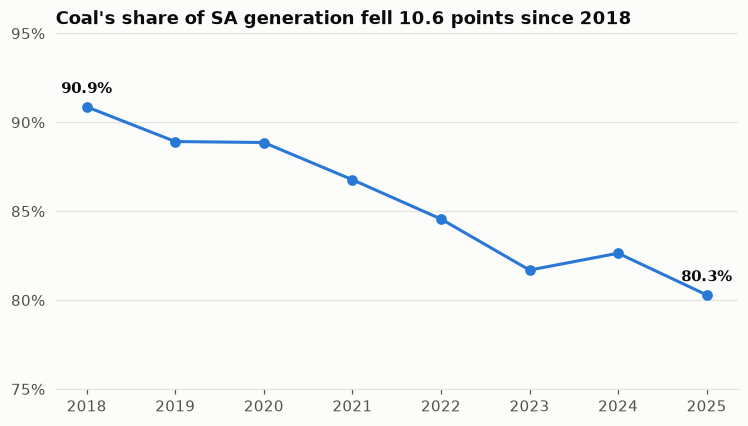

In [2]:
fig, ax = plt.subplots()
ax.plot(years, coal_share, color=SERIES[0], marker="o")
for x, y in [(years[0], coal_share[0]), (years[-1], coal_share[-1])]:
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontweight="bold")
ax.set_ylim(75, 95)
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_title(f"Coal's share of SA generation fell {coal_share[0] - coal_share[-1]:.1f} points since {years[0]}")
ax.set_xticks(years)
save(fig, "01_coal_share")
plt.show()

## 2. Wind and solar output

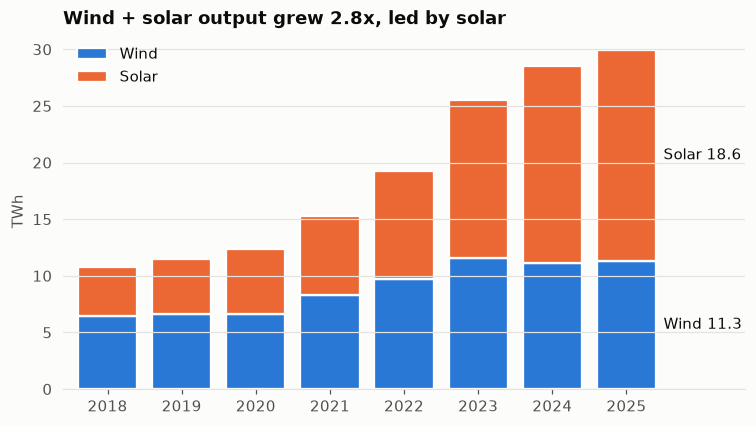

Solar: 4.3 -> 18.6 TWh (4.3x)
Wind:  6.5 -> 11.3 TWh (1.8x)
Share of generation: 4.2% -> 12.9%


In [3]:
ws = dict(((y, f), t) for y, f, t in con.execute('''
    select year(month), fuel, sum(generation_twh)
    from staging.stg_generation_monthly
    where fuel in ('Wind', 'Solar') and year(month) between ? and ?
    group by all
''', [years[0], years[-1]]).fetchall())
wind = [ws[(y, "Wind")] for y in years]
solar = [ws[(y, "Solar")] for y in years]

fig, ax = plt.subplots()
ax.bar(years, wind, color=SERIES[0], edgecolor="white", linewidth=1.5, label="Wind")
ax.bar(years, solar, bottom=wind, color=SERIES[1], edgecolor="white", linewidth=1.5, label="Solar")
# Direct labels on the latest bar so identity isn't carried by color alone
ax.text(years[-1] + 0.5, wind[-1] / 2, f"Wind {wind[-1]:.1f}", va="center")
ax.text(years[-1] + 0.5, wind[-1] + solar[-1] / 2, f"Solar {solar[-1]:.1f}", va="center")
ax.set_xlim(years[0] - 0.6, years[-1] + 1.6)
ax.set_xticks(years)
ax.set_ylabel("TWh")
ax.set_title(f"Wind + solar output grew {(wind[-1] + solar[-1]) / (wind[0] + solar[0]):.1f}x, led by solar")
ax.legend(loc="upper left")
save(fig, "02_wind_solar")
plt.show()

print(f"Solar: {solar[0]:.1f} -> {solar[-1]:.1f} TWh ({solar[-1] / solar[0]:.1f}x)")
print(f"Wind:  {wind[0]:.1f} -> {wind[-1]:.1f} TWh ({wind[-1] / wind[0]:.1f}x)")
print(f"Share of generation: {ws_share[0]:.1f}% -> {ws_share[-1]:.1f}%")

## 3. Total generation and the 2023 trough

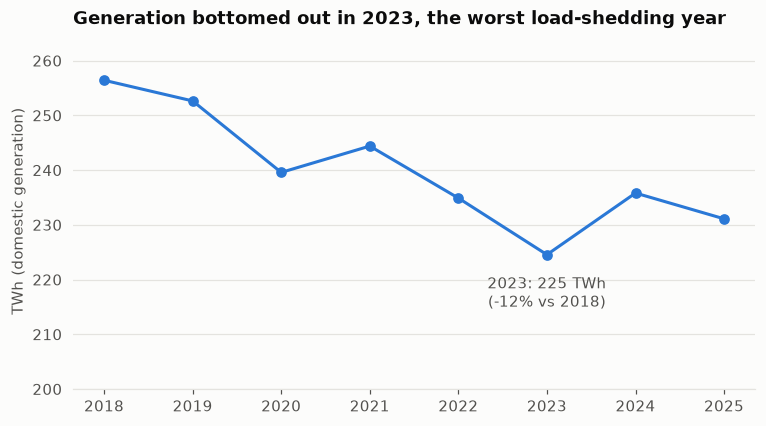

In [4]:
low = min(range(len(years)), key=lambda i: gen[i])

fig, ax = plt.subplots()
ax.plot(years, gen, color=SERIES[0], marker="o")
ax.annotate(f"{years[low]}: {gen[low]:.0f} TWh\n({(gen[low] / gen[0] - 1) * 100:.0f}% vs {years[0]})",
            (years[low], gen[low]), textcoords="offset points", xytext=(0, -34), ha="center", color=TEXT_SECONDARY)
ax.set_ylim(200, 265)
ax.set_xticks(years)
ax.set_ylabel("TWh (domestic generation)")
ax.set_title(f"Generation bottomed out in {years[low]}, the worst load-shedding year")
save(fig, "03_generation")
plt.show()

## Findings

1. **Coal is losing share steadily, but slowly.** It went from about 91% of generation in 2018 to about 80% in 2025, roughly 1.5 points a year. At that pace coal still produces most of SA's power well into the 2030s.
2. **Solar is the growth story.** Utility-scale solar went up more than 4x (≈4 → ≈19 TWh) and wind went up ≈1.8x, so wind + solar now provide ≈13% of generation.
3. **2023 was the low point.** Domestic generation fell ≈12% from 2018 to 2023, then partly recovered in 2024.

**Caveat:** lower generation doesn't by itself prove load shedding. Rooftop solar, which grid data largely misses, and weaker industrial demand also reduce what the grid supplies. Telling these apart is the job of the **Eskom hourly data**. For example, we can check whether demand ran into *available capacity* during the 2023 evening peaks.

## Next questions (notebook 02, Eskom hourly)
- How many hours per year did demand exceed available capacity?
- Do unplanned outages (UCLF) follow a seasonal pattern, and did they drive the 2024 recovery?
- How does the daily demand shape change as solar grows (the "duck curve")?